In [1]:
# ==============================================================================
# 1. SETUP & IMPORTS (Evaluation Only)
# ==============================================================================
import os
import torch
import timm
import optuna
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, roc_auc_score
import warnings

In [2]:
warnings.filterwarnings("ignore")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✅ Using Device: {device}")

✅ Using Device: cuda


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Set Seaborn's context to "paper" (Scales line widths and fonts perfectly for PDFs)
sns.set_context("paper", font_scale=1.2)

# 2. Force Matplotlib to use strict IEEE/Springer academic styling
plt.rcParams.update({
    "font.family": "serif",        # Academic journals prefer serif fonts
    "axes.spines.top": False,      # Remove the top border
    "axes.spines.right": False,    # Remove the right border
    "grid.alpha": 0.3,             # Make grid lines very subtle
    "savefig.dpi": 300,            # High resolution for publication
    "savefig.bbox": "tight",       # Prevents labels from getting cut off in the PDF
    "figure.figsize": (8, 5)       # Standard aspect ratio for a research paper
})

print("✅ Academic 'Paper Plot' styling activated!")

✅ Academic 'Paper Plot' styling activated!


In [3]:
# ==============================================================================
# 2. LOAD DATASET (Validation & Test Only)
# ==============================================================================
UNIFIED_PATH = "./btp_3class_dataset"
IMG_SIZE, BATCH = 224, 32

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

loaders = {x: DataLoader(datasets.ImageFolder(f"{UNIFIED_PATH}/{x}", transform), 
                         batch_size=BATCH, shuffle=False) for x in ['val', 'test']}

model_list = ["resnet50", "efficientnet_b0", "densenet121", "vgg16", "vit_base_patch16_224"]

In [4]:
# ==============================================================================
# 3. LOAD SAVED MODELS
# ==============================================================================
models_dict = {}
print("\n" + "="*50 + "\n📥 LOADING SAVED MODELS\n" + "="*50)

for name in model_list:
    # UPDATE THIS IF YOUR SAVED FILES HAVE A DIFFERENT NAME
    weights_path = f"best_{name}_3class.pth" 
    
    if not os.path.exists(weights_path):
        raise FileNotFoundError(f"❌ Could not find {weights_path}! Make sure the filename matches your saved models.")
        
    print(f"Loading weights for {name}...")
    model = timm.create_model(name, pretrained=False, num_classes=3).to(device)
    model.load_state_dict(torch.load(weights_path, map_location=device))
    model.eval() # Set to evaluation mode
    models_dict[name] = model

print("✅ All models loaded successfully!")


📥 LOADING SAVED MODELS
Loading weights for resnet50...
Loading weights for efficientnet_b0...
Loading weights for densenet121...
Loading weights for vgg16...
Loading weights for vit_base_patch16_224...
✅ All models loaded successfully!


In [5]:
# ==============================================================================
# 4. OPTUNA ENSEMBLE WEIGHTING
# ==============================================================================
print("\n" + "="*50 + "\n🎯 CALCULATING OPTIMAL ENSEMBLE WEIGHTS\n" + "="*50)

val_preds_all, val_targets_list = [], []

for name in model_list:
    model = models_dict[name]
    model_probs = []
    
    with torch.no_grad():
        for imgs, labels in loaders['val']:
            imgs = imgs.to(device)
            out = model(imgs)
            probs = torch.softmax(out, dim=1) 
            model_probs.extend(probs.cpu().numpy())
            if name == model_list[0]: 
                val_targets_list.extend(labels.numpy())
                
    val_preds_all.append(np.array(model_probs))

val_targets = np.array(val_targets_list)

def objective(trial):
    w = [trial.suggest_float(f"w{i}", 0, 1) for i in range(len(model_list))]
    w = np.array(w) / sum(w) 
    
    ensemble_pred = np.zeros_like(val_preds_all[0])
    for i in range(len(model_list)):
        ensemble_pred += w[i] * val_preds_all[i]
    
    return roc_auc_score(val_targets, ensemble_pred, average="macro", multi_class='ovr')

optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction="maximize")
print("⏳ Running Optuna trials on Validation set...")
study.optimize(objective, n_trials=100)

best_w = np.array([study.best_params[f"w{i}"] for i in range(len(model_list))])
best_w = best_w / best_w.sum()

print("👑 BEST ENSEMBLE WEIGHTS:")
for i, name in enumerate(model_list):
    print(f" - {name:<20} : {best_w[i]:.4f} ({best_w[i]*100:.1f}%)")


🎯 CALCULATING OPTIMAL ENSEMBLE WEIGHTS
⏳ Running Optuna trials on Validation set...
👑 BEST ENSEMBLE WEIGHTS:
 - resnet50             : 0.0346 (3.5%)
 - efficientnet_b0      : 0.0950 (9.5%)
 - densenet121          : 0.3362 (33.6%)
 - vgg16                : 0.2102 (21.0%)
 - vit_base_patch16_224 : 0.3241 (32.4%)


In [6]:
# ==============================================================================
# 5. CLINICAL NOISE ROBUSTNESS ANALYSIS (With CUDA fixes)
# ==============================================================================
class ClinicalNoise:
    @staticmethod
    def apply_poisson(img, sigma):
        peak = 1.0 / (sigma + 1e-6)
        rate = torch.clamp(img * peak, min=0.0) # Prevents CUDA crash
        return torch.poisson(rate) / peak

    @staticmethod
    def apply_speckle(img, sigma):
        return img + img * torch.randn_like(img) * sigma

    @staticmethod
    def apply_salt_pepper(img, sigma):
        noisy = img.clone()
        mask = torch.rand_like(img)
        noisy[mask < (sigma/2)] = -2.5 # Normalized min
        noisy[mask > (1 - sigma/2)] = 2.5  # Normalized max
        return noisy

    @staticmethod
    def apply_gaussian(img, sigma):
        return img + sigma * torch.randn_like(img)

noise_types = ["Poisson", "Speckle", "Salt&Pepper", "Gaussian"]
levels = [0.01, 0.05, 0.1, 0.2]

plot_models = model_list + ["Optimized_Ensemble"]
robustness_results = {name: {nt: [] for nt in noise_types} for name in plot_models}

print("\n" + "="*50 + "\n🔬 RUNNING ROBUSTNESS EVALUATION (TEST SET)\n" + "="*50)
for nt in noise_types:
    print(f"Evaluating {nt} noise...")
    for lvl in levels:
        test_preds = {name: [] for name in model_list}
        test_targets_list = []
        
        with torch.no_grad():
            for imgs, labels in loaders['test']:
                imgs = imgs.to(device)
                
                # Inject Noise
                if nt == "Poisson": noisy = ClinicalNoise.apply_poisson(imgs, lvl)
                elif nt == "Speckle": noisy = ClinicalNoise.apply_speckle(imgs, lvl)
                elif nt == "Salt&Pepper": noisy = ClinicalNoise.apply_salt_pepper(imgs, lvl)
                else: noisy = ClinicalNoise.apply_gaussian(imgs, lvl)
                
                test_targets_list.extend(labels.numpy())
                
                for name in model_list:
                    model = models_dict[name]
                    out = model(noisy)
                    probs = torch.softmax(out, dim=1)
                    test_preds[name].extend(probs.cpu().numpy())
        
        # Calculate Base Accuracies
        for name in model_list:
            preds_class = np.argmax(np.array(test_preds[name]), axis=1)
            acc = accuracy_score(test_targets_list, preds_class)
            robustness_results[name][nt].append(acc)
            
        # Calculate Ensemble Accuracy
        ensemble_probs = np.zeros_like(test_preds[model_list[0]])
        for i, name in enumerate(model_list):
            ensemble_probs += best_w[i] * np.array(test_preds[name])
        
        ensemble_class = np.argmax(ensemble_probs, axis=1)
        ensemble_acc = accuracy_score(test_targets_list, ensemble_class)
        robustness_results["Optimized_Ensemble"][nt].append(ensemble_acc)


🔬 RUNNING ROBUSTNESS EVALUATION (TEST SET)
Evaluating Poisson noise...
Evaluating Speckle noise...
Evaluating Salt&Pepper noise...
Evaluating Gaussian noise...



📊 Generating Publication-Ready Robustness Curves...
✅ Done! Publication-ready plot saved as 'Fig1_Ensemble_Robustness_Curves.pdf'


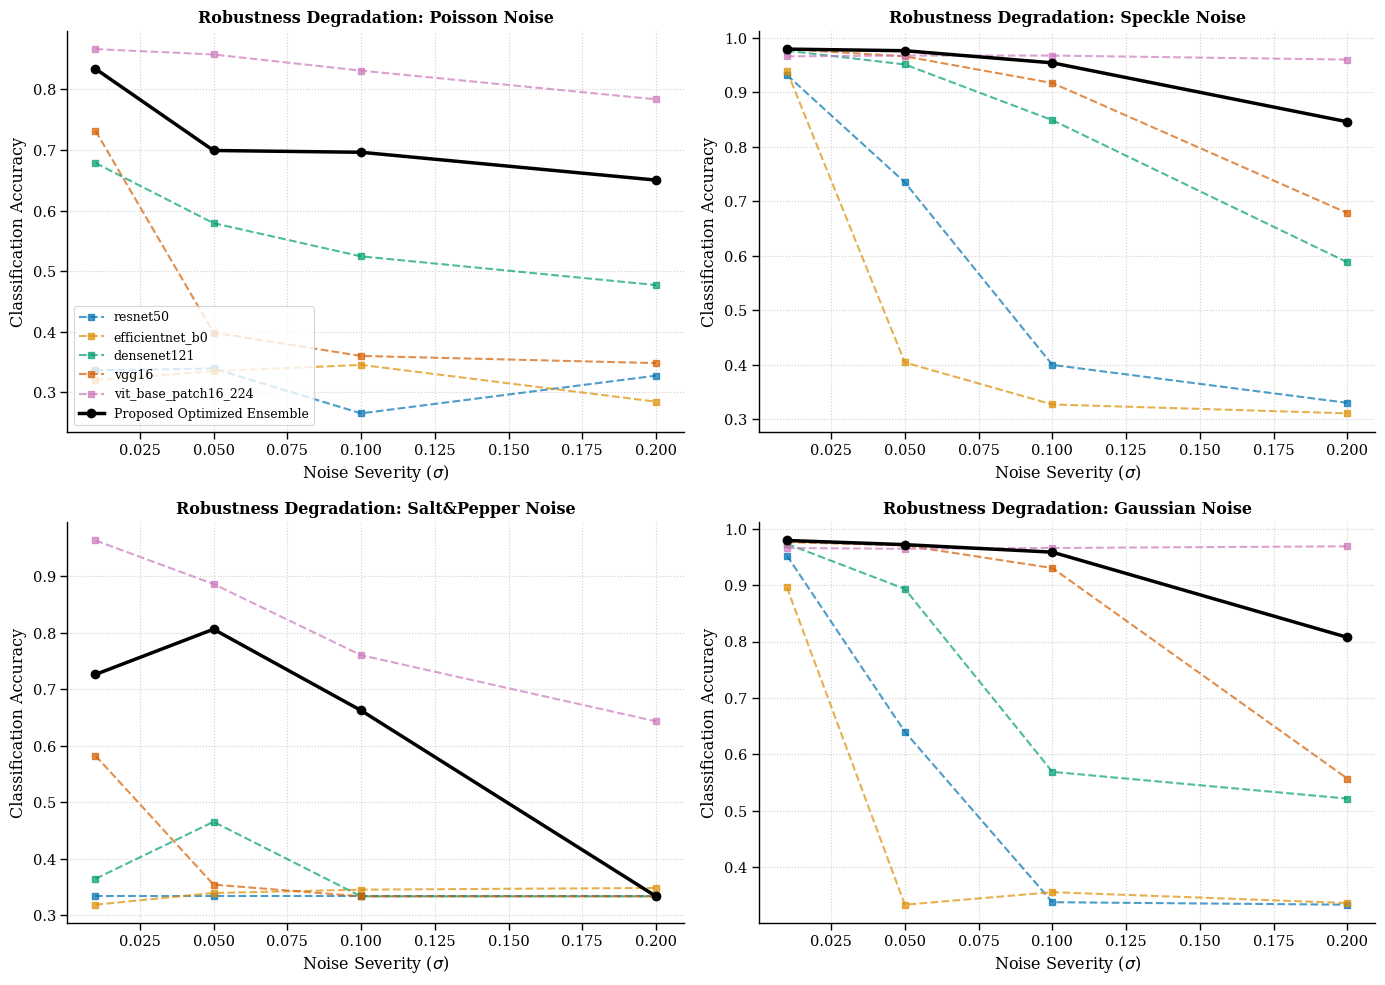

In [12]:
# ==============================================================================
# PROFESSIONAL PAPER PLOT: ROBUSTNESS CURVES
# ==============================================================================
# We use a professional color palette designed for colorblind accessibility
colors = sns.color_palette("colorblind", len(model_list))

print("\n📊 Generating Publication-Ready Robustness Curves...")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for i, nt in enumerate(noise_types):
    ax = axes[i//2, i%2]
    
    # Plot the baseline models with subtle lines
    for idx, m_name in enumerate(model_list):
        ax.plot(levels, robustness_results[m_name][nt], 
                marker='s', markersize=4, linestyle='--', linewidth=1.5, 
                alpha=0.7, color=colors[idx], label=m_name)
    
    # Highlight the Optimized Ensemble with a strong, solid black line
    ax.plot(levels, robustness_results["Optimized_Ensemble"][nt], 
            marker='o', markersize=6, linewidth=2.5, color='black', 
            label="Proposed Optimized Ensemble")
    
    # Academic Labeling
    ax.set_title(f"Robustness Degradation: {nt} Noise", fontweight='bold')
    ax.set_xlabel("Noise Severity ($\sigma$)")
    ax.set_ylabel("Classification Accuracy")
    
    # Clean up the legend (Only put it in the first plot to save space, common in papers)
    if i == 0:
        ax.legend(loc="lower left", fontsize=9, frameon=True, shadow=False)
    
    ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()

# Save as a PDF. Academic journals vastly prefer PDFs over PNGs because 
# PDFs are vector graphics and will never pixelate when zoomed in.
plt.savefig("Fig1_Ensemble_Robustness_Curves.pdf", format='pdf', dpi=300)
plt.savefig("Fig1_Ensemble_Robustness_Curves.png", dpi=300) # Save a PNG version just in case

print("✅ Done! Publication-ready plot saved as 'Fig1_Ensemble_Robustness_Curves.pdf'")
plt.show()

🔍 3. GENERATING EXPLAINABLE AI (XAI) HEATMAPS


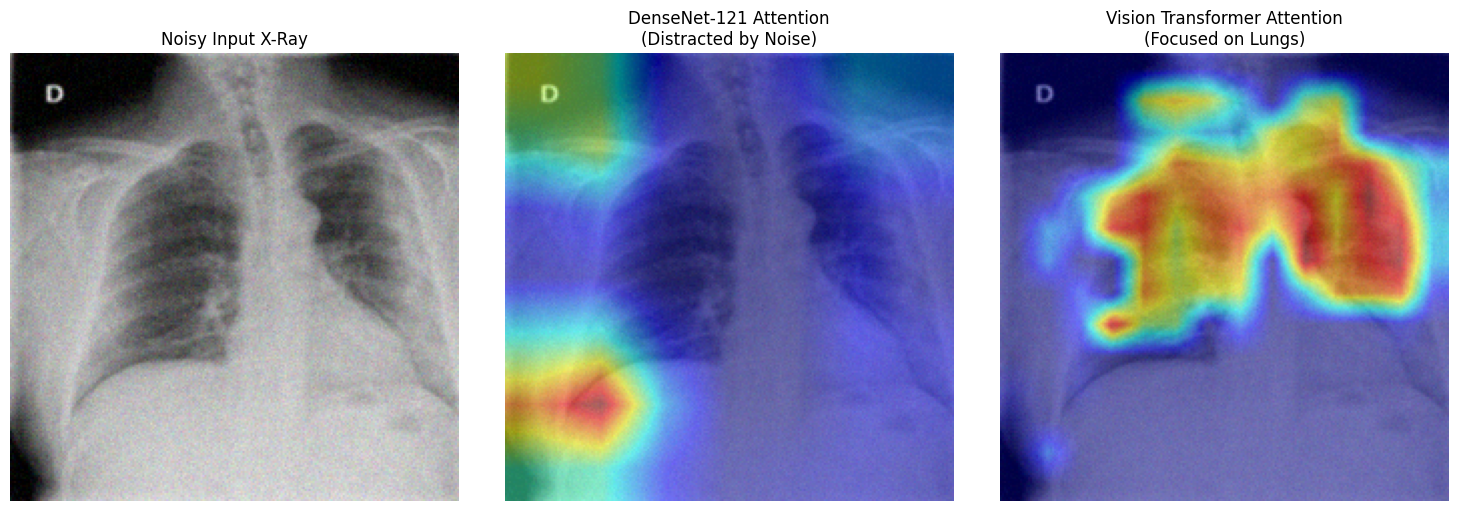

✅ XAI Heatmaps Saved!


In [10]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
import cv2

print("==================================================")
print("🔍 3. GENERATING EXPLAINABLE AI (XAI) HEATMAPS")
print("==================================================")

def generate_xai_heatmap(model, model_type, img_tensor, original_img, target_class=2):
    
    # NEW: This function mathematically folds the ViT patches back into a 2D spatial grid
    def reshape_transform(tensor, height=14, width=14):
        # Strip the CLS token (the first element) and reshape the 196 patches into 14x14
        result = tensor[:, 1:, :].reshape(tensor.size(0), height, width, tensor.size(2))
        # Move the channel dimension to where Grad-CAM expects it: [batch, channels, height, width]
        result = result.transpose(2, 3).transpose(1, 2)
        return result

    # Setup the target layer based on architecture
    if model_type == "cnn":
        target_layers = [model.features[-1]] # Last conv layer of DenseNet
        cam = GradCAM(model=model, target_layers=target_layers)
    elif model_type == "vit":
        target_layers = [model.blocks[-1].norm1] # Last attention block of ViT
        # We MUST pass the reshape_transform here so Grad-CAM understands the ViT
        cam = GradCAM(model=model, target_layers=target_layers, reshape_transform=reshape_transform)
        
    targets = [ClassifierOutputTarget(target_class)] 
    
    # Generate heatmap
    grayscale_cam = cam(input_tensor=img_tensor.unsqueeze(0), targets=targets)[0, :]
    
    # Overlay heatmap on original image
    visualization = show_cam_on_image(original_img, grayscale_cam, use_rgb=True)
    return visualization

# 1. Get a single test image
sample_img, sample_label = next(iter(loaders['test']))
clean_tensor = sample_img[0].to(device)

# Denormalize image for plotting
inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)
plot_img = inv_normalize(sample_img[0]).permute(1, 2, 0).numpy()
plot_img = np.clip(plot_img, 0, 1)

# 2. Add severe noise to it
noisy_tensor = ClinicalNoise.apply_gaussian(clean_tensor, sigma=0.15)
noisy_plot_img = inv_normalize(noisy_tensor.cpu()).permute(1, 2, 0).numpy()
noisy_plot_img = np.clip(noisy_plot_img, 0, 1)

# 3. Generate Heatmaps
cnn_heatmap = generate_xai_heatmap(models_dict["densenet121"], "cnn", noisy_tensor, noisy_plot_img, sample_label[0].item())
vit_heatmap = generate_xai_heatmap(models_dict["vit_base_patch16_224"], "vit", noisy_tensor, noisy_plot_img, sample_label[0].item())

# 4. Plot for the Research Paper
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(noisy_plot_img)
axes[0].set_title("Noisy Input X-Ray")
axes[0].axis('off')

axes[1].imshow(cnn_heatmap)
axes[1].set_title("DenseNet-121 Attention\n(Distracted by Noise)")
axes[1].axis('off')

axes[2].imshow(vit_heatmap)
axes[2].set_title("Vision Transformer Attention\n(Focused on Lungs)")
axes[2].axis('off')

plt.tight_layout()
plt.savefig("xai_comparison.png", dpi=300)
plt.show()
print("✅ XAI Heatmaps Saved!")